# Unidad 2 — Ejemplo 1: PCA para reducir la dimensión

**Objetivo:** pasar de muchas variables observadas a unas pocas variables latentes (componentes principales), conservando la mayor parte posible de la variabilidad.

Trabajaremos con `clientes_multidimensional.csv`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

pd.set_option("display.max_columns", None)
df = pd.read_csv("clientes_multidimensional.csv")
df.head()

,id_cliente,sesiones_mes,minutos_mes,dispositivos,descargas_mes,valoracion,soporte_contactos,gasto_anual,antiguedad_meses,edad,plan,pais,descargas_activas
0,1001,17.72,704.27,2,10.96,6.10,4.06,102.60,15.90,30.39,Básico,Francia,Sí
1,1002,17.92,696.88,2,13.77,5.89,4.01,111.45,35.48,34.53,Estándar,Italia,No
2,1003,10.22,781.80,3,13.13,7.46,2.58,125.44,32.85,37.06,Estándar,Francia,Sí
3,1004,2.00,127.88,1,8.14,6.76,1.27,93.27,11.79,27.77,Estándar,España,No
4,1005,32.43,1339.74,3,22.72,5.94,1.55,118.09,25.88,42.84,Premium,Italia,Sí


## 1. Exploración inicial

El conjunto contiene variables numéricas y categóricas. Para PCA utilizaremos únicamente variables numéricas de entrada.

**Importante:** PCA no debe recibir directamente identificadores ni variables categóricas sin codificar.

In [2]:
df.info()
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id_cliente         240 non-null    int64  
 1   sesiones_mes       240 non-null    float64
 2   minutos_mes        240 non-null    float64
 3   dispositivos       240 non-null    int64  
 4   descargas_mes      240 non-null    float64
 5   valoracion         240 non-null    float64
 6   soporte_contactos  240 non-null    float64
 7   gasto_anual        240 non-null    float64
 8   antiguedad_meses   240 non-null    float64
 9   edad               240 non-null    float64
 10  plan               240 non-null    object 
 11  pais               240 non-null    object 
 12  descargas_activas  240 non-null    object 
dtypes: float64(8), int64(2), object(3)
memory usage: 24.5+ KB


,count,mean,std,min,25%,50%,75%,max
id_cliente,240.0,1120.500000,69.426220,1001.00,1060.7500,1120.500,1180.2500,1240.00
sesiones_mes,240.0,18.487000,9.096151,2.00,12.3350,17.810,25.0500,43.00
minutos_mes,240.0,926.096917,438.177179,80.00,639.1600,896.555,1213.0725,2225.48
dispositivos,240.0,2.583333,1.055635,1.00,2.0000,2.500,3.0000,5.00
descargas_mes,240.0,12.465833,6.670743,0.00,7.8100,12.310,17.0900,32.50
valoracion,240.0,6.162250,0.960844,3.03,5.6100,6.215,6.8125,8.56
soporte_contactos,240.0,3.002458,1.173054,0.21,2.2100,2.965,3.7525,6.89
gasto_anual,240.0,111.421542,15.541320,63.71,100.6950,111.005,120.9625,162.14
antiguedad_meses,240.0,25.125958,10.573007,1.00,17.2600,24.675,32.5075,56.13
edad,240.0,38.871542,9.189071,18.00,32.8975,38.865,44.5450,66.81


In [3]:
numericas = [
    "sesiones_mes", "minutos_mes", "dispositivos", "descargas_mes",
    "valoracion", "soporte_contactos", "gasto_anual",
    "antiguedad_meses", "edad"
]

X = df[numericas].copy()
X.shape

(240, 9)

## 2. ¿Por qué estandarizar antes de PCA?

PCA busca direcciones de máxima varianza. Si una variable está medida en una escala mucho mayor que otra, puede dominar el resultado.

Por eso, en este ejemplo:

1. seleccionamos las variables numéricas;
2. las estandarizamos;
3. aplicamos PCA.

La transformación debe formar parte del flujo de entrenamiento para evitar inconsistencias y fugas de información.

In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pd.DataFrame(X_scaled, columns=numericas).describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
sesiones_mes,240.0,-0.0,1.002,-1.816,-0.678,-0.075,0.723,2.701
minutos_mes,240.0,-0.0,1.002,-1.935,-0.656,-0.068,0.656,2.972
dispositivos,240.0,-0.0,1.002,-1.503,-0.554,-0.079,0.396,2.294
descargas_mes,240.0,0.0,1.002,-1.873,-0.699,-0.023,0.695,3.010
valoracion,240.0,-0.0,1.002,-3.267,-0.576,0.055,0.678,2.501
soporte_contactos,240.0,0.0,1.002,-2.385,-0.677,-0.032,0.641,3.321
gasto_anual,240.0,0.0,1.002,-3.076,-0.692,-0.027,0.615,3.270
antiguedad_meses,240.0,0.0,1.002,-2.287,-0.746,-0.043,0.700,2.939
edad,240.0,0.0,1.002,-2.276,-0.651,-0.001,0.619,3.047


## 3. PCA inicial: conservar 95 % de la varianza

En lugar de fijar arbitrariamente el número de componentes, podemos pedir a PCA que conserve el 95 % de la varianza.

In [5]:
pca_95 = PCA(n_components=0.95, random_state=42)
X_pca = pca_95.fit_transform(X_scaled)

print("Dimensión original:", X.shape[1])
print("Número de componentes:", pca_95.n_components_)
print("Varianza acumulada:", pca_95.explained_variance_ratio_.cumsum())

Dimensión original: 9
Número de componentes: 6
Varianza acumulada: [0.42615397 0.62968651 0.74956755 0.85340974 0.91853177 0.95131681]


## 4. Varianza explicada

Cada componente es una combinación lineal de las variables originales.

- PC1 explica la mayor parte de la varianza.
- PC2 explica la siguiente mayor parte.
- etc.

La pregunta importante no es solo «¿cuántas columnas tengo?», sino **«¿cuánta información/variabilidad pierdo al reducirlas?»**.

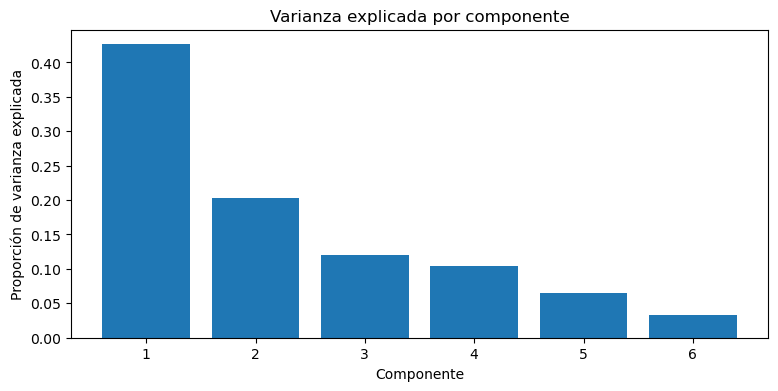

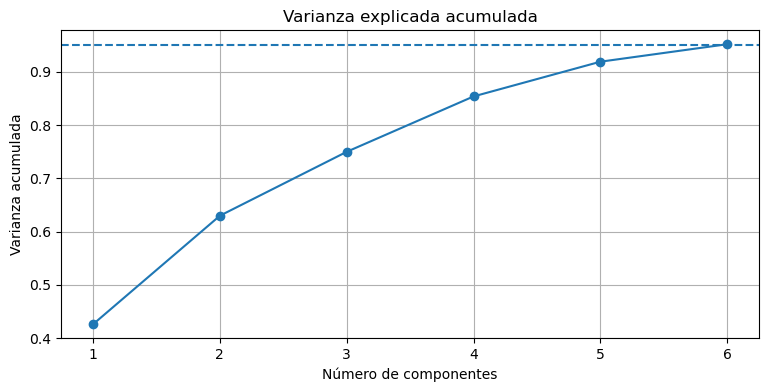

In [6]:
var = pca_95.explained_variance_ratio_
plt.figure(figsize=(9,4))
plt.bar(range(1, len(var)+1), var)
plt.xlabel("Componente")
plt.ylabel("Proporción de varianza explicada")
plt.title("Varianza explicada por componente")
plt.show()

plt.figure(figsize=(9,4))
plt.plot(range(1, len(var)+1), var.cumsum(), marker="o")
plt.axhline(0.95, linestyle="--")
plt.xlabel("Número de componentes")
plt.ylabel("Varianza acumulada")
plt.title("Varianza explicada acumulada")
plt.grid()
plt.show()

## 5. Interpretar los componentes: cargas (loadings)

Las cargas indican cuánto participa cada variable original en cada componente.

No conviene interpretar una componente solo por su nombre. Debemos mirar sus cargas y justificar qué patrón común representan.

In [7]:
loadings = pd.DataFrame(
    pca_95.components_.T,
    index=numericas,
    columns=[f"PC{i+1}" for i in range(pca_95.n_components_)]
)

loadings.round(3)

,PC1,PC2,PC3,PC4,PC5,PC6
sesiones_mes,0.445,0.197,0.218,0.207,0.024,0.208
minutos_mes,0.456,0.251,0.085,0.093,0.108,0.094
dispositivos,0.427,-0.174,0.110,0.160,-0.246,-0.391
descargas_mes,0.448,0.258,0.070,0.028,0.184,0.063
valoracion,0.232,0.111,-0.602,-0.496,0.467,-0.196
soporte_contactos,-0.022,-0.531,0.211,0.337,0.746,-0.050
gasto_anual,0.303,-0.486,-0.091,-0.114,-0.287,-0.461
antiguedad_meses,0.255,-0.517,-0.215,-0.179,-0.171,0.733
edad,0.018,-0.059,0.683,-0.719,0.089,-0.010


In [8]:
for col in loadings.columns[:min(3, len(loadings.columns))]:
    print("\n", col)
    print(loadings[col].sort_values(key=np.abs, ascending=False).head(5))


 PC1
minutos_mes      0.455513
descargas_mes    0.448132
sesiones_mes     0.445091
dispositivos     0.426951
gasto_anual      0.302564
Name: PC1, dtype: float64

 PC2
soporte_contactos   -0.531475
antiguedad_meses    -0.517181
gasto_anual         -0.485594
descargas_mes        0.257743
minutos_mes          0.251039
Name: PC2, dtype: float64

 PC3
edad                 0.683140
valoracion          -0.602150
sesiones_mes         0.218338
antiguedad_meses    -0.214811
soporte_contactos    0.210547
Name: PC3, dtype: float64


## 6. Crear la copia reducida del conjunto

Podemos querer crear una copia del conjunto con las transformaciones ya aplicadas.

Aquí construimos un nuevo DataFrame con las componentes. Conservamos el identificador solo para poder relacionar cada muestra con el registro original; **no participa en PCA**.

In [9]:
df_reducido = pd.DataFrame(
    X_pca,
    columns=[f"PC{i+1}" for i in range(pca_95.n_components_)]
)

df_reducido.insert(0, "id_cliente", df["id_cliente"].values)
df_reducido["gasto_anual"] = df["gasto_anual"].values

df_reducido.head()

,id_cliente,PC1,PC2,PC3,PC4,PC5,PC6,gasto_anual
0,1001,-1.053102,0.189873,-0.301245,1.064406,0.911598,-0.264200,102.60
1,1002,-0.256975,-0.966178,-0.287709,0.450280,0.412162,0.902124,111.45
2,1003,0.436356,-0.769775,-1.442229,-1.038931,-0.175238,-0.494939,125.44
3,1004,-3.094979,1.427889,-1.898735,-0.382552,-0.356974,-0.424904,93.27
4,1005,2.103001,1.230262,0.686849,-0.164244,-0.806575,0.309056,118.09


In [10]:
df_reducido.to_csv("clientes_multidimensional_reducido_PCA.csv",
                      index=False, encoding="utf-8-sig")
print("Archivo creado: clientes_multidimensional_reducido_PCA.csv")

Archivo creado: clientes_multidimensional_reducido_PCA.csv


## 7. Flujo correcto durante entrenamiento

Para un modelo predictivo real, el escalado y PCA deben aprenderse **solo con el conjunto de entrenamiento**.

`Pipeline` permite encapsular ambos pasos y aplicar exactamente la misma transformación en entrenamiento, validación y test.

In [11]:
X_model = df[numericas].drop(columns=["gasto_anual"])
y = df["gasto_anual"]

X_train, X_test, y_train, y_test = train_test_split(
    X_model, y, test_size=0.2, random_state=42
)

pipeline_pca = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.95, random_state=42))
])

X_train_red = pipeline_pca.fit_transform(X_train)
X_test_red = pipeline_pca.transform(X_test)

print("Train original:", X_train.shape)
print("Train reducido:", X_train_red.shape)
print("Test reducido:", X_test_red.shape)

Train original: (192, 8)
Train reducido: (192, 6)
Test reducido: (48, 6)


## 8. Conclusiones del ejemplo

- PCA reduce la dimensión creando variables latentes.
- La estandarización es importante cuando las escalas son diferentes.
- `n_components=0.95` selecciona automáticamente los componentes necesarios para conservar el 95 % de la varianza.
- La matriz de cargas ayuda a interpretar las componentes.
- La transformación debe aprenderse con entrenamiento y reutilizarse con `transform()` en datos nuevos.
- La copia reducida puede guardarse para posteriores análisis.

## 9. Parámetros que deben documentarse

Para este experimento debemos registrar, como mínimo:

| Elemento | Valor |
|---|---|
| Técnica | PCA |
| Preprocesado | StandardScaler |
| Varianza objetivo | 95 % |
| `random_state` | 42 |
| Variables de entrada | 8 variables predictoras |
| Resultado | número de componentes obtenido |
| Fichero generado | `clientes_multidimensional_reducido_PCA.csv` |


## 10. Actividad

Ejecuta el notebook y completa la tabla con el número real de componentes y la varianza acumulada obtenida.

Crea un gráfico **Scree Plot** conjunto en el que aparezca la varianza explicada por cada variable y la varianza acumulada en un único gráfico.